## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from data_prep import load_raw_data, preprocess_extended_games, preprocess_train_data, split_test
from content_based import build_cb_model, build_user_item_matrix_cb, recommend_cb, score_cb
from collaborative_filtering import build_binary_matrix, build_user_item_matrix_cf, item_cosine_similarity, topk_filter, recommend_cf, score_cf
from fwls_hybrid import project_cf_to_cb_space, minmax_normalize, combine_scores, recommend_hybrid, check_alpha
from adaptive_hybrid import count_interactions, combine_scores_adaptive, switched_alpha, check_threshold
from reranking import popularity_penalty_rerank, mmr_rerank, check_gamma, check_lambda
from reranking_extended import fairness_penalty_rerank, publisher_capital, check_beta
from submission import export_results
from metrics import ndcg_at_k, recall_at_k, item_gini, intra_list_similarity, select_best_param, per_user_ndcg, per_user_ils

## Preprocessing

In [2]:
extended_games_raw, train_data_raw, test_data_raw = load_raw_data() #load raw data
#preprocess
extended_games = preprocess_extended_games(extended_games_raw)
train_data = preprocess_train_data(train_data_raw)

BEFORE CLEANING: 0 missing item_id, 0 missing item_name, 0 duplicate item_id
AFTER CLEANING: item_id and item_name are unique non-null
Columns with missing values BEFORE: ['about_the_game', 'detailed_description', 'reviews']
AFTER: Confirmed no missing values remain
AFTER: 0 games with no parsed publisher
BEFORE CLEANING: 26596 duplicate (user_id, item_id) pairs found
AFTER: 0 duplicate pairs remaining after dedup
AFTER: 0 rows with negative playtime
Columns with missing values in training data: []


In [3]:
extended_games.head(3)

,item_id,item_name,publishers,positive,negative,recommendations,short_description,about_the_game,detailed_description,reviews,publishers_list,publisher
0,0,Counter-Strike,['Valve'],198387,5135,122770,Play the world's number 1 online action game. ...,Play the world's number 1 online action game. ...,Play the world's number 1 online action game. ...,,[Valve],Valve
1,1,Rag Doll Kung Fu,['Mark Healey'],55,23,0,A piece of Steam history - THE FIRST EVER NON ...,A piece of Steam history - THE FIRST EVER NON ...,A piece of Steam history - THE FIRST EVER NON ...,,[Mark Healey],Mark Healey
2,2,Silo 2,['Nevercenter Ltd. Co.'],57,25,0,"Silo is a focused, lightning-fast standalone 3...",Note: This is a legacy version of Silo which i...,Note: This is a legacy version of Silo which i...,,[Nevercenter Ltd. Co.],Nevercenter Ltd. Co.


Split test data into fold-in / hold-out

In [4]:
test_in_df, test_out_df = split_test(test_data_raw)

## Content-Based Model

In [5]:
extended_games_cleaned, lda_model, similarity_matrix, id_index, index_id = build_cb_model(extended_games)

0 games have zero tokens AFTER PREPROCESSING
Training LDA model with 20 topics on 6753 documents...
Training done!
0 topic(s) have zero probability mass across all documents
CB model built: 6753 items, 20 topics


In [6]:
#Generate recommendations
user_ids = test_in_df["user_id"].unique().tolist()
user_item_matrix = build_user_item_matrix_cb(test_in_df, user_ids, id_index)
cb_recommendations = recommend_cb(user_item_matrix, similarity_matrix, index_id, topn=20)

Generating top-20 CB recommendations for 12464 users...
Done. 0 users received no recommendations


In [7]:
#Evaluate model
cb_ndcg = ndcg_at_k(cb_recommendations, user_ids, test_out_df, k=20)
cb_recall = recall_at_k(cb_recommendations, user_ids, test_out_df, k=20)
cb_gini = item_gini(cb_recommendations, k=20)
cb_ils = intra_list_similarity(cb_recommendations, similarity_matrix, id_index, k=20)

print("CB results (@20):")
print(f"  NDCG:      {cb_ndcg:.4f}")
print(f"  Recall:    {cb_recall:.4f}")
print(f"  Item Gini: {cb_gini:.4f}")
print(f"  ILS:       {cb_ils:.4f}")

CB results (@20):
  NDCG:      0.0115
  Recall:    0.0157
  Item Gini: 0.8258
  ILS:       0.7262


## Collaborative Filtering

In [8]:
all_users, all_items, user2row, item2col = build_binary_matrix(train_data, test_in_df)

print("Training dataset:")
X_train = build_user_item_matrix_cf(train_data, user2row, item2col)
print("Fold-in dataset:")
X_test_in = build_user_item_matrix_cf(test_in_df, user2row, item2col)

cf_similarity_matrix = item_cosine_similarity(X_train) #cosine similarity on shared interactions
cf_similarity_matrix = topk_filter(cf_similarity_matrix, k=200) #ItemKNN
#Generate recommendations
cf_recommendations = recommend_cf(X_test_in, cf_similarity_matrix, all_items, topn=20)

Training dataset:
User-item matrix for CF: 66779 users x 8475 items, 2267389 interactions
Fold-in dataset:
User-item matrix for CF: 66779 users x 8475 items, 352743 interactions
Calculating the 200 nearest neighbours for 8475 items...
Top-200 item-item similarity matrix calculated
Generating top-20 CF recommendations for 66779 users...
Done. 0 users received no recommendations.


In [9]:
cf_ndcg = ndcg_at_k(cf_recommendations, all_users, test_out_df, k=20)
cf_recall = recall_at_k(cf_recommendations, all_users, test_out_df, k=20)
cf_gini = item_gini(cf_recommendations, k=20)
cf_ils = intra_list_similarity(cf_recommendations, cf_similarity_matrix, item2col, k=20)

print("CF results (@20):")
print(f"  NDCG:      {cf_ndcg:.4f}")
print(f"  Recall:    {cf_recall:.4f}")
print(f"  Item Gini: {cf_gini:.4f}")
print(f"  ILS:       {cf_ils:.4f}")

CF results (@20):
  NDCG:      0.2358
  Recall:    0.3125
  Item Gini: 0.9727
  ILS:       0.0818


## FWLS Hybrid Recommender

In [10]:
#get the raw scores from each model for every candidate item, soy they can be
#be projected into a shared space, normalized, and combined into the hybrid score
cb_item_ids = extended_games_cleaned["item_id"].tolist()

cb_scores_raw = score_cb(user_item_matrix, similarity_matrix)
cf_scores_raw = score_cf(X_test_in, cf_similarity_matrix)

In [11]:
#project CF's global scores down into CB's smaller space
cf_scores_projected = project_cf_to_cb_space(
    cf_scores_raw, all_users, all_items, user_ids, cb_item_ids
)

Starting CF->CB projection: reducing 66779 users x 8475 items (CF space) down to 12464 users x 6753 items (CB space)...
CF->CB projection COMPLETED: 42 CB items not found in global CF space, 0 CB users not found in global CF space


In [12]:
#normalize both scores to [0,1] per user, so neither dominates due to scale
cb_scores_norm = minmax_normalize(cb_scores_raw)
cf_scores_norm = minmax_normalize(cf_scores_projected)

In [13]:
#different values of alpha to find the best balance between CF and CB
alpha_results = check_alpha(
    cf_scores_norm, cb_scores_norm, user_item_matrix, cb_item_ids,
    user_ids, test_out_df, topn=20
)

alpha=0.00 | ndcg@20=0.0115 | recall@20=0.0157 | gini@20=0.8258
alpha=0.10 | ndcg@20=0.0350 | recall@20=0.0440 | gini@20=0.8335
alpha=0.20 | ndcg@20=0.0702 | recall@20=0.0839 | gini@20=0.8535
alpha=0.30 | ndcg@20=0.1125 | recall@20=0.1401 | gini@20=0.8903
alpha=0.40 | ndcg@20=0.1512 | recall@20=0.2022 | gini@20=0.9362
alpha=0.50 | ndcg@20=0.1779 | recall@20=0.2418 | gini@20=0.9595
alpha=0.60 | ndcg@20=0.1998 | recall@20=0.2692 | gini@20=0.9656
alpha=0.70 | ndcg@20=0.2166 | recall@20=0.2873 | gini@20=0.9681
alpha=0.80 | ndcg@20=0.2277 | recall@20=0.2961 | gini@20=0.9684
alpha=0.90 | ndcg@20=0.2316 | recall@20=0.2984 | gini@20=0.9641
alpha=1.00 | ndcg@20=0.2279 | recall@20=0.2955 | gini@20=0.9590


In [14]:
alpha_df = pd.DataFrame(alpha_results)
best_alpha = alpha_df.loc[alpha_df["ndcg"].idxmax(), "alpha"]
print(f"Best alpha by NDCG: {best_alpha:.2f}")

hybrid_scores_final = combine_scores(cf_scores_norm, cb_scores_norm, best_alpha)
hybrid_recommendations = recommend_hybrid(hybrid_scores_final, user_item_matrix, cb_item_ids, topn=20)

Best alpha by NDCG: 0.90


In [15]:
#Export results to test them in the Codabench
export_results(hybrid_recommendations, user_ids, path="submission_fwls.csv", topn=20)

Submission covers 12464/12464 users, avg 20.0 recommendations per user
Saved submission_fwls.csv
Zipped to submission_fwls.csv.zip — upload this file to Codabench


,user_id,item_id
0,4,8205
1,4,39
2,4,8363
3,4,8213
4,4,658
...,...,...
249275,68397,4301
249276,68397,6032
249277,68397,847
249278,68397,5522


## User-Adaptive Hybrid Recommender

In [16]:
#interactions per user, aligned with user_ids order
interaction_counts = count_interactions(test_in_df, user_ids)

In [17]:
threshold_results = check_threshold(
    cf_scores_norm, cb_scores_norm, user_item_matrix, cb_item_ids,
    user_ids, interaction_counts, test_out_df, topn=20
)
threshold_df = pd.DataFrame(threshold_results)
best_T = threshold_df.loc[threshold_df["ndcg"].idxmax(), "T"]
print(f"Best T by NDCG: {best_T}")

T=  1 | ndcg@20=0.2316 | recall@20=0.2984 | gini@20=0.9641
T=  2 | ndcg@20=0.2270 | recall@20=0.2889 | gini@20=0.9696
T=  3 | ndcg@20=0.2216 | recall@20=0.2787 | gini@20=0.9662
T=  5 | ndcg@20=0.2052 | recall@20=0.2501 | gini@20=0.9466
T=  8 | ndcg@20=0.1934 | recall@20=0.2315 | gini@20=0.9347
T= 13 | ndcg@20=0.1771 | recall@20=0.2076 | gini@20=0.9184
T= 21 | ndcg@20=0.1587 | recall@20=0.1842 | gini@20=0.9081
T= 34 | ndcg@20=0.1378 | recall@20=0.1628 | gini@20=0.8990
Best T by NDCG: 1


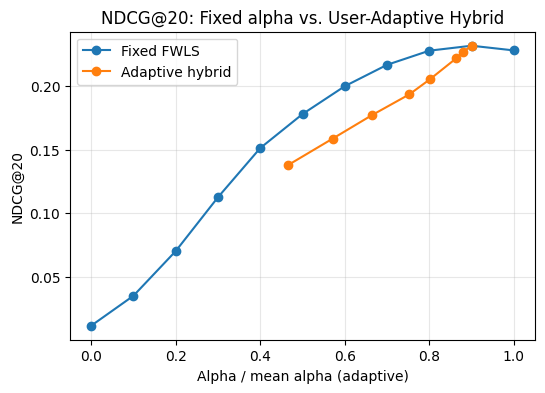

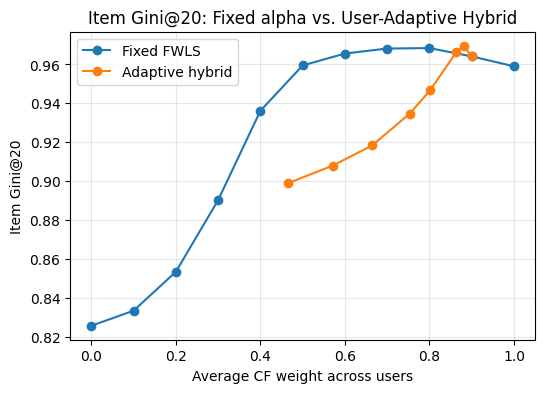

In [18]:
mean_alphas = [
    switched_alpha(interaction_counts, T, alpha_low=0.3, alpha_high=0.9).mean()
    for T in threshold_df["T"]
]
threshold_df["mean_alpha"] = mean_alphas

plt.figure(figsize=(6, 4))
plt.plot(alpha_df["alpha"], alpha_df["ndcg"], marker="o", color="tab:blue", label="Fixed FWLS")
plt.plot(threshold_df["mean_alpha"], threshold_df["ndcg"], marker="o", color="tab:orange", label="Adaptive hybrid")
plt.xlabel("Alpha / mean alpha (adaptive)")
plt.ylabel("NDCG@20")
plt.title("NDCG@20: Fixed alpha vs. User-Adaptive Hybrid")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(alpha_df["alpha"], alpha_df["gini"], marker="o", color="tab:blue", label="Fixed FWLS")
plt.plot(threshold_df["mean_alpha"], threshold_df["gini"], marker="o", color="tab:orange", label="Adaptive hybrid")
plt.xlabel("Average CF weight across users")
plt.ylabel("Item Gini@20")
plt.title("Item Gini@20: Fixed alpha vs. User-Adaptive Hybrid")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
#We create the recommendations with T = 1
alpha_per_user_final = switched_alpha(interaction_counts, T=best_T, alpha_low=0.3, alpha_high=0.9)
scores_adaptive_final = combine_scores_adaptive(cf_scores_norm, cb_scores_norm, alpha_per_user_final)
adaptive_recommendations = recommend_hybrid(scores_adaptive_final, user_item_matrix, cb_item_ids, topn=20)

In [20]:
export_results(adaptive_recommendations, user_ids, path="submission_adaptive.csv", topn=20)

Submission covers 12464/12464 users, avg 20.0 recommendations per user
Saved submission_adaptive.csv
Zipped to submission_adaptive.csv.zip — upload this file to Codabench


,user_id,item_id
0,4,8205
1,4,39
2,4,8363
3,4,8213
4,4,658
...,...,...
249275,68397,4301
249276,68397,6032
249277,68397,847
249278,68397,5522


## Reranking Methods

In [21]:
#mask seen items
hybrid_scores_masked = hybrid_scores_final.copy()
seen_mask = user_item_matrix.toarray().astype(bool)
hybrid_scores_masked[seen_mask] = -np.inf

In [22]:
#Popularity Penalty — check the best values of gamma
gamma_results = check_gamma(
    hybrid_scores_masked, cb_item_ids, train_data, user_ids, user_item_matrix,
    test_out_df, similarity_matrix, id_index, topn=20
)
gamma_df = pd.DataFrame(gamma_results)

Applying popularity penalty with gamma=0.00
gamma=0.00 | ndcg=0.2316 | recall=0.2984 | gini=0.9641 | ils=0.2417
Applying popularity penalty with gamma=0.10
gamma=0.10 | ndcg=0.2274 | recall=0.2965 | gini=0.9659 | ils=0.2442
Applying popularity penalty with gamma=0.20
gamma=0.20 | ndcg=0.2177 | recall=0.2909 | gini=0.9656 | ils=0.2474
Applying popularity penalty with gamma=0.30
gamma=0.30 | ndcg=0.2022 | recall=0.2795 | gini=0.9650 | ils=0.2519
Applying popularity penalty with gamma=0.40
gamma=0.40 | ndcg=0.1809 | recall=0.2528 | gini=0.9639 | ils=0.2571
Applying popularity penalty with gamma=0.50
gamma=0.50 | ndcg=0.1621 | recall=0.2218 | gini=0.9632 | ils=0.2629
Applying popularity penalty with gamma=0.60
gamma=0.60 | ndcg=0.1505 | recall=0.2015 | gini=0.9619 | ils=0.2694
Applying popularity penalty with gamma=0.70
gamma=0.70 | ndcg=0.1401 | recall=0.1837 | gini=0.9600 | ils=0.2760
Applying popularity penalty with gamma=0.80
gamma=0.80 | ndcg=0.1320 | recall=0.1745 | gini=0.9578 | ils

In [23]:
#MMR — check best values of lambda
lambda_results = check_lambda(
    hybrid_scores_masked, similarity_matrix, cb_item_ids, user_ids,
    test_out_df, id_index, topn=20
)
lambda_df = pd.DataFrame(lambda_results)

Applying MMR reranking with lambda=0.00 for 12464 users
lambda=0.00 | ndcg=0.0045 | recall=0.0031 | gini=0.8744 | ils=0.0752
Applying MMR reranking with lambda=0.10 for 12464 users
lambda=0.10 | ndcg=0.1203 | recall=0.1087 | gini=0.8858 | ils=0.0878
Applying MMR reranking with lambda=0.20 for 12464 users
lambda=0.20 | ndcg=0.1449 | recall=0.1566 | gini=0.9330 | ils=0.0915
Applying MMR reranking with lambda=0.30 for 12464 users
lambda=0.30 | ndcg=0.1674 | recall=0.2005 | gini=0.9540 | ils=0.1048
Applying MMR reranking with lambda=0.40 for 12464 users
lambda=0.40 | ndcg=0.1823 | recall=0.2279 | gini=0.9610 | ils=0.1184
Applying MMR reranking with lambda=0.50 for 12464 users
lambda=0.50 | ndcg=0.1940 | recall=0.2474 | gini=0.9627 | ils=0.1345
Applying MMR reranking with lambda=0.60 for 12464 users
lambda=0.60 | ndcg=0.2060 | recall=0.2672 | gini=0.9628 | ils=0.1502
Applying MMR reranking with lambda=0.70 for 12464 users
lambda=0.70 | ndcg=0.2170 | recall=0.2839 | gini=0.9623 | ils=0.1707


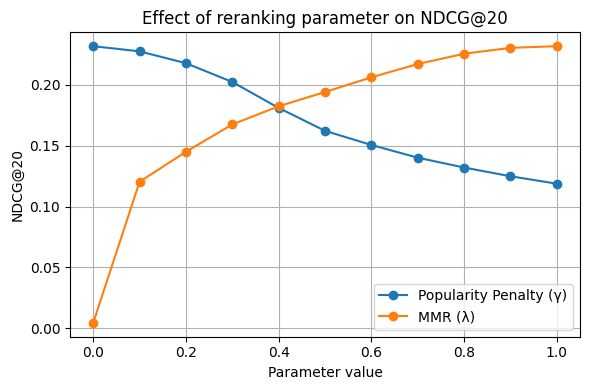

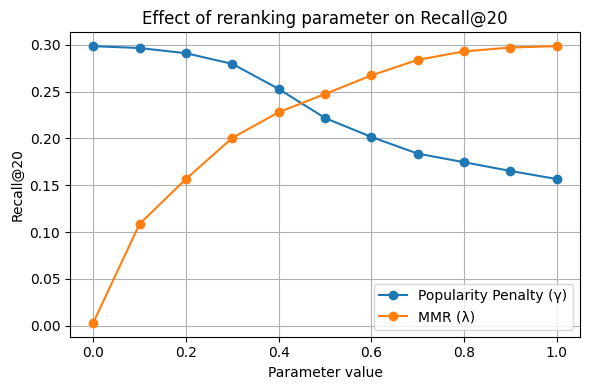

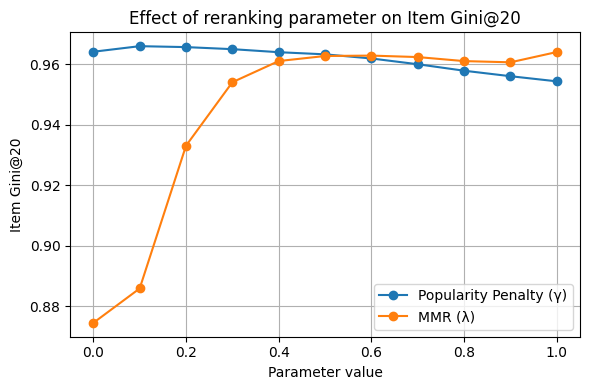

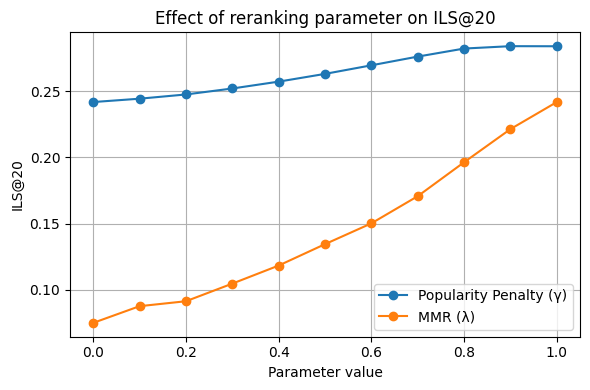

In [24]:
metric_labels = {"ndcg": "NDCG@20", "recall": "Recall@20", "gini": "Item Gini@20", "ils": "ILS@20"}

for metric in ["ndcg", "recall", "gini", "ils"]:
    plt.figure(figsize=(6, 4))
    plt.plot(gamma_df["param"], gamma_df[metric], marker="o", label="Popularity Penalty (γ)")
    plt.plot(lambda_df["param"], lambda_df[metric], marker="o", label="MMR (λ)")
    plt.xlabel("Parameter value")
    plt.ylabel(metric_labels[metric])
    plt.title(f"Effect of reranking parameter on {metric_labels[metric]}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

#### Publisher Fairness Reranking

In [25]:
item_to_publisher = dict(zip(extended_games_cleaned["item_id"], extended_games_cleaned["publisher"])) #assign each game to it's publisher

desired_exposure = publisher_capital(extended_games_cleaned, alpha=0.75)

PCA - first component explains 75.3% of variance across 3527 publishers
Weights: games=0.158, positive=0.571, negative=0.569, recommendations=0.571


In [26]:
beta_results = check_beta(
    hybrid_scores_masked, cb_item_ids, item_to_publisher, desired_exposure,
    user_ids, user_item_matrix, test_out_df, similarity_matrix, id_index, topn=20
)
beta_df = pd.DataFrame(beta_results)

Applying fairness reranking with beta=0.00: 
beta=0.00 | ndcg=0.2316 | recall=0.2984 | gini=0.9641 | ils=0.2417 | fairness=1.8533
Applying fairness reranking with beta=0.10: 
beta=0.10 | ndcg=0.2217 | recall=0.2873 | gini=0.9592 | ils=0.2229 | fairness=2.3317
Applying fairness reranking with beta=0.20: 
beta=0.20 | ndcg=0.1149 | recall=0.2000 | gini=0.9605 | ils=0.2106 | fairness=2.0292
Applying fairness reranking with beta=0.30: 
beta=0.30 | ndcg=0.0562 | recall=0.0837 | gini=0.9638 | ils=0.2025 | fairness=1.6806
Applying fairness reranking with beta=0.40: 
beta=0.40 | ndcg=0.0483 | recall=0.0659 | gini=0.9650 | ils=0.2076 | fairness=1.5990
Applying fairness reranking with beta=0.50: 
beta=0.50 | ndcg=0.0451 | recall=0.0588 | gini=0.9652 | ils=0.2133 | fairness=1.5711
Applying fairness reranking with beta=0.60: 
beta=0.60 | ndcg=0.0436 | recall=0.0544 | gini=0.9653 | ils=0.2174 | fairness=1.5573
Applying fairness reranking with beta=0.70: 
beta=0.70 | ndcg=0.0431 | recall=0.0534 | gin

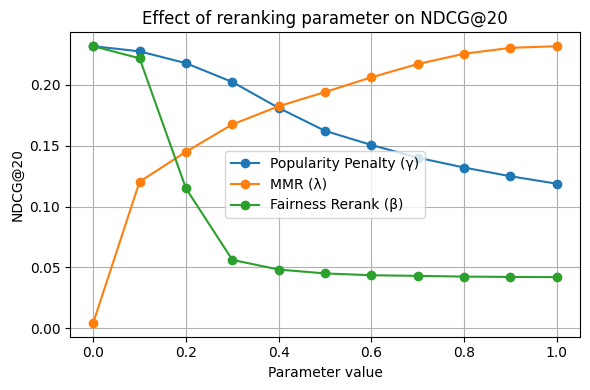

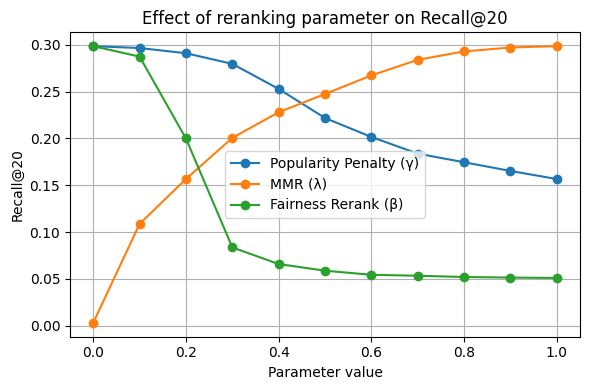

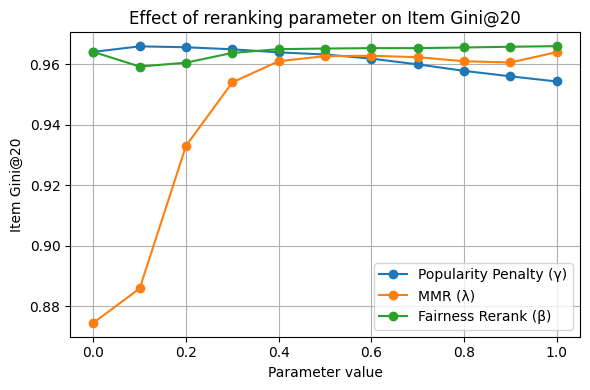

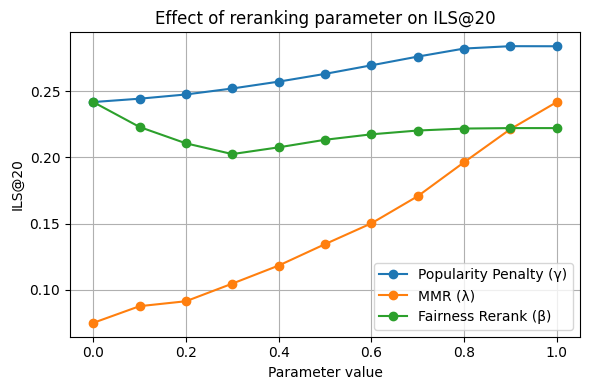

In [27]:
metric_labels = {"ndcg": "NDCG@20", "recall": "Recall@20", "gini": "Item Gini@20", "ils": "ILS@20"}

for metric in ["ndcg", "recall", "gini", "ils"]:
    plt.figure(figsize=(6, 4))
    plt.plot(gamma_df["param"], gamma_df[metric], marker="o", label="Popularity Penalty (γ)")
    plt.plot(lambda_df["param"], lambda_df[metric], marker="o", label="MMR (λ)")
    plt.plot(beta_df["param"], beta_df[metric], marker="o", label="Fairness Rerank (β)")
    plt.xlabel("Parameter value")
    plt.ylabel(metric_labels[metric])
    plt.title(f"Effect of reranking parameter on {metric_labels[metric]}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

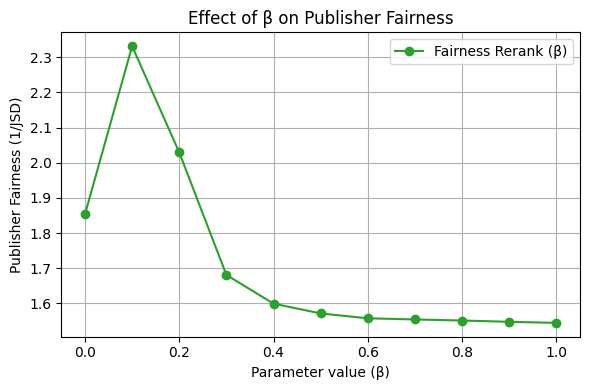

In [28]:
plt.figure(figsize=(6, 4))
plt.plot(beta_df["param"], beta_df["fairness"], marker="o", color="tab:green", label="Fairness Rerank (β)")
plt.xlabel("Parameter value (β)")
plt.ylabel("Publisher Fairness (1/JSD)")
plt.title("Effect of β on Publisher Fairness")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Final Results and Recommendations

In [29]:
#We select the best value for each parameter
print("Popularity Penalty (gamma):")
best_gamma = select_best_param(gamma_df, baseline_param=0, metric_col="ils", higher_is_better=False)

print("\nMMR (lambda):")
best_lambda = select_best_param(lambda_df, baseline_param=1.0, metric_col="ils", higher_is_better=False)

print("\nFairness Rerank (beta):")
best_beta = select_best_param(beta_df, baseline_param=0, metric_col="fairness", higher_is_better=True)

Popularity Penalty (gamma):
Chosen param=0.0 | ndcg=0.2316 | recall=0.2984 | gini=0.9641 | ils=0.2417

MMR (lambda):
Chosen param=0.4 | ndcg=0.1823 | recall=0.2279 | gini=0.9610 | ils=0.1184

Fairness Rerank (beta):
Chosen param=0.1 | ndcg=0.2217 | recall=0.2873 | gini=0.9592 | ils=0.2229 | fairness=2.3317


In [30]:
#Create recommendations
scores_pop_final = popularity_penalty_rerank(hybrid_scores_masked, cb_item_ids, train_data, gamma=best_gamma, topn=20)
final_pop_recs = recommend_hybrid(scores_pop_final, user_item_matrix, cb_item_ids, topn=20)

final_mmr_recs = mmr_rerank(hybrid_scores_masked, similarity_matrix, cb_item_ids, lam=best_lambda, topn=20)

scores_fair_final = fairness_penalty_rerank(hybrid_scores_masked, cb_item_ids, item_to_publisher, desired_exposure, beta=best_beta, topn=20)
final_fairness_recs = recommend_hybrid(scores_fair_final, user_item_matrix, cb_item_ids, topn=20)

Applying popularity penalty with gamma=0.00
Applying MMR reranking with lambda=0.40 for 12464 users
Applying fairness reranking with beta=0.10: 


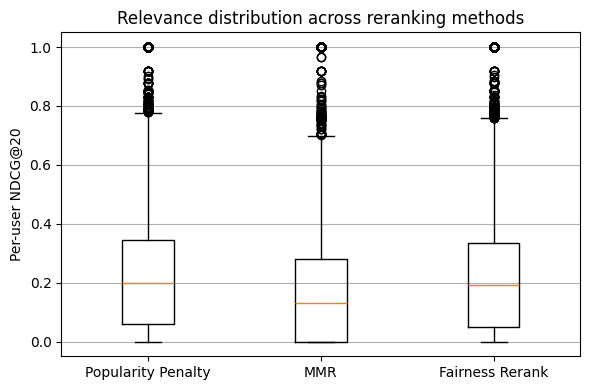

In [31]:
ndcg_pop = per_user_ndcg(final_pop_recs, user_ids, test_out_df, k=20)
ndcg_mmr = per_user_ndcg(final_mmr_recs, user_ids, test_out_df, k=20)
ndcg_fair = per_user_ndcg(final_fairness_recs, user_ids, test_out_df, k=20)

plt.figure(figsize=(6, 4))
plt.boxplot([ndcg_pop, ndcg_mmr, ndcg_fair], tick_labels=["Popularity Penalty", "MMR", "Fairness Rerank"])
plt.ylabel("Per-user NDCG@20")
plt.title("Relevance distribution across reranking methods")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

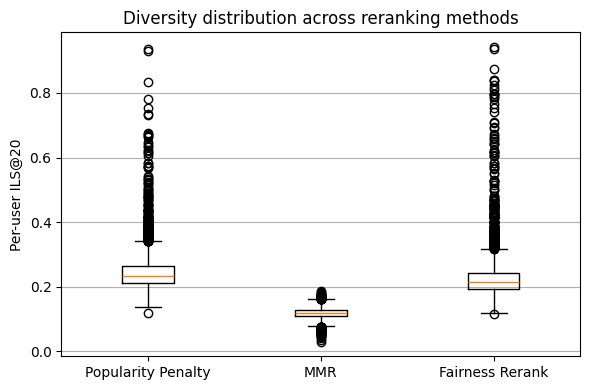

In [32]:
ils_pop = per_user_ils(final_pop_recs, similarity_matrix, id_index, k=20)
ils_mmr = per_user_ils(final_mmr_recs, similarity_matrix, id_index, k=20)
ils_fair = per_user_ils(final_fairness_recs, similarity_matrix, id_index, k=20)

plt.figure(figsize=(6, 4))
plt.boxplot([ils_pop, ils_mmr, ils_fair], tick_labels=["Popularity Penalty", "MMR", "Fairness Rerank"])
plt.ylabel("Per-user ILS@20")
plt.title("Diversity distribution across reranking methods")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

In [33]:
#Export these other results
export_results(final_mmr_recs, user_ids, path="submission_mmr.csv", topn=20)

Submission covers 12464/12464 users, avg 20.0 recommendations per user
Saved submission_mmr.csv
Zipped to submission_mmr.csv.zip — upload this file to Codabench


,user_id,item_id
0,4,8205
1,4,39
2,4,307
3,4,450
4,4,1043
...,...,...
249275,68397,870
249276,68397,1269
249277,68397,7572
249278,68397,5208


In [34]:
export_results(final_fairness_recs, user_ids, path="submission_fairness.csv", topn=20)

Submission covers 12464/12464 users, avg 20.0 recommendations per user
Saved submission_fairness.csv
Zipped to submission_fairness.csv.zip — upload this file to Codabench


,user_id,item_id
0,4,8205
1,4,658
2,4,39
3,4,8363
4,4,450
...,...,...
249275,68397,2143
249276,68397,8260
249277,68397,2340
249278,68397,4709
